# Notebook 2 — 从零实现二维避障任务、lean AM 与改进候选

**这是一份实际训练 notebook，不是读取历史结果的包装器。**
从行为策略生成数据，拟合 scalar critics，再训练 actor；代码全部在本文件展开。
不使用 `runtime.replay()`、预训练 critic 或预先记录的性能曲线。

要检验的 motivation 是：终点梯度标签的误差会不会经 lean adjoint 影响 actor 更新。
本任务**不**给梯度加噪声，也**不**加入解析实验的振荡项。
critic 的误差来自有限行为数据、真实观测噪声、函数近似及有限拟合预算。
本 notebook 不预设“值误差一定足够小”或“改进一定胜出”；这两点必须看测量结果。

**比较方法**：

| 方法 | 变化 | actor 优化器 |
|---|---|---|
| AM + Adam | 原始 ReLU ensemble、lean AM | Adam |
| AM 2x | 每步 128 条轨迹；其余不变 | Adam |
| Nominal guard | 每 20 步，用 ensemble 均值做有限步长检查 | 原始 Adam 提议 |
| Robust guard | 同一终点 critic 混合权重下的最坏有限代价差检查 | 原始 Adam 提议 |
| SiLU + AM | 仅替换 critic 激活函数，作为梯度标签估计的消融 | Adam |

Robust guard 是 **HJBI/minimax 思想启发的经验 safeguard**，不是推导出的新 HJBI PDE，
不保证真实代价下降，也不保证 ensemble 包含真实终点梯度。SiLU 是估计器消融，不是新 AM。
这些都是已有开发候选；本次不根据输出再调参数、加 seed 或筛选场景。
更早的 RBF/residual 候选仍完整保留在仓库历史总览中，此处不把它们删掉或改成成功。

三个预定 seeds：18001、18002、18003。所有候选训练 1000 步，使用末次 actor；
评价结果不会决定 actor checkpoint。运行需要 CPU 数分钟，内存建议至少 2 GB。
在项目依赖环境中 Run All，或直接执行同名 `.py`。输出放入唯一的 `runs/02-navigation-*`。

In [1]:
import copy
import hashlib
import json
import math
import platform
import tempfile
import time
from contextlib import contextmanager
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import numpy as np
import pandas as pd
import scipy
from scipy.optimize import minimize
from scipy.stats import t as student_t
import torch
from torch import nn
from IPython.display import display, Markdown

torch.set_num_threads(1)
START = time.monotonic()
RUNS = Path.cwd() / 'runs'
RUNS.mkdir(exist_ok=True)
OUT = Path(tempfile.mkdtemp(prefix='02-navigation-', dir=RUNS))
VERSIONS = dict(python=platform.python_version(), torch=torch.__version__,
                numpy=np.__version__, scipy=scipy.__version__,
                pandas=pd.__version__, matplotlib=matplotlib.__version__,
                device='cpu', threads=torch.get_num_threads())
CHECKS = []


def check(name, condition):
    CHECKS.append(dict(name=name, passed=bool(condition)))
    assert condition, name


def savefig(fig, name):
    fig.savefig(OUT/f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()


def rng(seed):
    return torch.Generator(device='cpu').manual_seed(int(seed))


def tensor(x):
    return torch.as_tensor(x, dtype=torch.float32)


@dataclass
class Config:
    # Only fields actually used by this navigation task; no inherited dead options.
    steps: int = 40
    horizon: float = 2.
    sigma: float = .5
    start: tuple = (-2., 0., 0., 0.)
    goal: tuple = (2., 0., 0., 0.)
    stiffness: float = .8
    damping: float = 1.
    base_arch: float = .9
    obstacles: tuple = ((-.65, .2, .4), (.65, -.2, .4))
    obstacle_weight: float = 55.
    terminal_weight: float = 1.
    velocity_weight: float = .25
    quartic_weight: float = 0.
    capture_reward: float = 35.
    capture_position_scale: float = .4
    capture_velocity_scale: float = .5
    outcome_std: float = .1
    velocity_outcome_std: float = .15
    success_radius: float = .4
    success_velocity: float = .5
    critic_train: int = 1024
    critic_valid: int = 512
    critic_mc: int = 4
    critic_updates: int = 2200
    critic_width: int = 128
    critic_lr: float = .002
    actor_width: int = 64

    @property
    def dt(self):
        return self.horizon / self.steps


@dataclass
class Options:
    updates: int = 1000
    batch: int = 64
    lr: float = .002
    block: int = 20
    guard_paths: int = 320
    alphas: tuple = (0., .25, .5, 1.)
    rho: float = .3
    validation_slack: float = .1
    eval_every: int = 100
    final_paths: int = 4096


CFG, OPT = Config(), Options()
SEEDS = (18001, 18002, 18003)
METHODS = ('am_adam', 'am_2x', 'nominal_guard', 'robust_guard', 'silu')
LABELS = dict(am_adam='AM + Adam', am_2x='AM 2x', nominal_guard='Nominal guard',
              robust_guard='Robust guard', silu='SiLU + AM')
PROTOCOL = dict(config=asdict(CFG), options=asdict(OPT), seeds=SEEDS, methods=METHODS,
                critic_members=5, critic_batch=128, critic_validation_every=50,
                actor_clip_norm=5., evaluation_paths=1024, fine_grid_paths=2048,
                checkpoint_selection='fixed final actor at 1000 updates',
                gradient_corruption='none', data='behavior rollouts and noisy physical outcome costs',
                development_seeds_reused=True, fresh_seed_confirmation=False)
PROTOCOL_SHA = hashlib.sha256(json.dumps(PROTOCOL, sort_keys=True).encode()).hexdigest()
(OUT/'protocol.json').write_text(json.dumps(PROTOCOL, indent=2))
display(pd.Series(VERSIONS, name='Execution environment').to_frame())
display(pd.Series(asdict(CFG), name='Task configuration').to_frame())

,Execution environment
python,3.13.11
torch,2.9.1
numpy,2.3.5
scipy,1.16.3
pandas,2.3.3
matplotlib,3.10.8
device,cpu
threads,1


,Task configuration
steps,40
horizon,2.0
sigma,0.5
start,"(-2.0, 0.0, 0.0, 0.0)"
goal,"(2.0, 0.0, 0.0, 0.0)"
stiffness,0.8
damping,1.0
base_arch,0.9
obstacles,"((-0.65, 0.2, 0.4), (0.65, -0.2, 0.4))"
obstacle_weight,55.0


## 1. 场景、动力学与固定真实目标

状态 \(x=(p_x,p_y,v_x,v_y)\in\mathbb R^4\)，控制 \(u\in\mathbb R^2\) 加在加速度通道，
二维仅指导航平面。已知基准漂移
\(b(x,t)=\dot m(t)+A(x-m(t))\)，其中共同的参考路线 \(m(t)\) 有上拱 .9；
**零控制本身已有一个有用的行为先验**，不是各方法从完全静止开始。
\[
dX_t=[b(X_t,t)+S u_\theta(X_t,t)]dt+S\,dW_t,\quad
S=.5\begin{bmatrix}0&0\\0&0\\1&0\\0&1\end{bmatrix},\quad T=2.
\]
\[
J(u)=\mathbb E\left[\int_0^T\left(\tfrac12\|u_t\|^2+\ell(X_t)\right)dt+g(X_T)\right].
\]
\(\ell\) 是两个障碍物周围的 Gaussian 软惩罚，**并非硬碰撞约束**。
另外独立报告线段穿过圆形障碍的碰撞率。

终点观测为 \(Y=X_T+\xi\)，位置测量标准差 .1、速度 .15。
单次实际代价是位置平方误差 + .25 倍速度平方误差
+ \(35[1-\exp(-\frac12\|(Y-x_{\rm goal})/(.4,.4,.5,.5)\|^2)]\)。
训练标签取 4 次独立实际观测的均值。真实 \(g(x)\) 是这一观测代价的期望。
\(\nabla g\) 与解析 \(g\) 仅供评价/机制诊断；learner 只看到观测值。
`quartic_weight=0`，没有启用历史配置中的四次惩罚。

下面的 reference、drift、rollout、观测代价及精确评价函数都是完整实现。

In [2]:
class TerminalCritic(nn.Module):
    def __init__(self,width=128):
        super().__init__();self.net=nn.Sequential(nn.Linear(4,width),nn.ReLU(),nn.Linear(width,width),nn.ReLU(),nn.Linear(width,1))
    def forward(self,x):return 20*self.net(x/tensor([3.,3.,2.,2.])).squeeze(-1)


class Controller(nn.Module):
    def __init__(self,width=64):
        super().__init__();self.net=nn.Sequential(nn.Linear(5,width),nn.Tanh(),nn.Linear(width,width),nn.Tanh(),nn.Linear(width,2))
        nn.init.zeros_(self.net[-1].weight);nn.init.zeros_(self.net[-1].bias)
    def forward(self,x,t):
        if not torch.is_tensor(t):t=torch.full_like(x[...,:1],float(t))
        return self.net(torch.cat([x/tensor([3.,3.,2.,2.]),t-1.],dim=-1))


def matrices(cfg,dt=None):
    dt=cfg.dt if dt is None else dt
    A=tensor([[0,0,1,0],[0,0,0,1],[-cfg.stiffness,0,-cfg.damping,0],[0,-cfg.stiffness,0,-cfg.damping]])
    S=cfg.sigma*tensor([[0,0],[0,0],[1,0],[0,1]])
    return A,torch.eye(4)+dt*A,S


def reference(t,cfg):
    s=t/cfg.horizon;disp=tensor(cfg.goal[:2])-tensor(cfg.start[:2])
    p=tensor(cfg.start[:2])+disp*(3*s*s-2*s*s*s)
    v=disp*(6*s-6*s*s)/cfg.horizon
    acc=disp*(6-12*s)/cfg.horizon**2
    # Optional pre-existing curved behavior prior, not a method-specific route.
    p=p+tensor([0.,cfg.base_arch*math.sin(math.pi*s)**2])
    v=v+tensor([0.,cfg.base_arch*math.pi/cfg.horizon*math.sin(2*math.pi*s)])
    acc=acc+tensor([0.,2*cfg.base_arch*(math.pi/cfg.horizon)**2*math.cos(2*math.pi*s)])
    return torch.cat([p,v]),torch.cat([v,acc])


def drift(x,t,cfg):
    A,_,_=matrices(cfg);m,mdot=reference(t,cfg)
    return mdot+(x-m)@A.T


@torch.no_grad()
def rollout(actor,cfg,n,generator,steps=None):
    steps=cfg.steps if steps is None else steps;dt=cfg.horizon/steps
    _,_,S=matrices(cfg)
    xs=[tensor(cfg.start).expand(n,-1).clone()];us=[]
    for k in range(steps):
        u=actor(xs[-1],k*dt);noise=torch.randn(n,2,generator=generator)
        xs.append(xs[-1]+dt*(drift(xs[-1],k*dt,cfg)+u@S.T)+math.sqrt(dt)*noise@S.T)
        us.append(u)
    return torch.stack(xs,1),torch.stack(us,1)


def offline_positions(n,cfg,generator):
    coefficients=torch.randn(n,3,2,generator=generator)*tensor([1.6,1.6])
    def behavior(x,t):
        phase=math.pi*t/cfg.horizon
        return coefficients[:,0]+coefficients[:,1]*math.sin(phase)+coefficients[:,2]*math.cos(phase)
    return rollout(behavior,cfg,n,generator)[0][:,-1]


def outcome_scales(cfg):return tensor([cfg.outcome_std,cfg.outcome_std,cfg.velocity_outcome_std,cfg.velocity_outcome_std])


def observed_terminal_cost(x,cfg,generator):
    y=x[:,None,:]+torch.randn(len(x),cfg.critic_mc,4,generator=generator)*outcome_scales(cfg)
    e=y-tensor(cfg.goal)
    cost=cfg.terminal_weight*e[...,:2].square().sum(-1)+cfg.velocity_weight*e[...,2:].square().sum(-1)
    cost+=cfg.quartic_weight*e[...,:2].pow(4).sum(-1)
    if cfg.capture_reward:
        scale=tensor([cfg.capture_position_scale]*2+[cfg.capture_velocity_scale]*2)
        cost+=cfg.capture_reward*(1-torch.exp(-.5*(e/scale).square().sum(-1)))
    return cost.mean(1)


def true_terminal_value(x,cfg):
    e=x-tensor(cfg.goal);var=outcome_scales(cfg).square()
    weights=tensor([cfg.terminal_weight]*2+[cfg.velocity_weight]*2)
    cost=((e.square()+var)*weights).sum(-1)
    cost+=cfg.quartic_weight*(e[...,:2].pow(4)+6*var[:2]*e[...,:2].square()+3*var[:2].square()).sum(-1)
    if cfg.capture_reward:
        s2=tensor([cfg.capture_position_scale**2]*2+[cfg.capture_velocity_scale**2]*2)
        capture=(s2/(s2+var)).sqrt().prod()*torch.exp(-.5*(e.square()/(s2+var)).sum(-1))
        cost+=cfg.capture_reward*(1-capture)
    return cost


def true_terminal_gradient(x,cfg):
    e=x-tensor(cfg.goal);var=outcome_scales(cfg).square()
    grad=2*e*tensor([cfg.terminal_weight]*2+[cfg.velocity_weight]*2)
    grad[...,:2]+=cfg.quartic_weight*(4*e[...,:2].pow(3)+12*var[:2]*e[...,:2])
    if cfg.capture_reward:
        s2=tensor([cfg.capture_position_scale**2]*2+[cfg.capture_velocity_scale**2]*2)
        capture=(s2/(s2+var)).sqrt().prod()*torch.exp(-.5*(e.square()/(s2+var)).sum(-1))
        grad+=cfg.capture_reward*capture[...,None]*e/(s2+var)
    return grad


def running_cost_and_gradient(x,cfg):
    cost=torch.zeros(x.shape[:-1]);grad=torch.zeros_like(x)
    for cx,cy,r in cfg.obstacles:
        d=x[...,:2]-tensor([cx,cy]);s=.85*r
        bump=cfg.obstacle_weight*torch.exp(-d.square().sum(-1)/(2*s*s))
        cost+=bump;grad[...,:2]-=bump[...,None]*d/(s*s)
    return cost,grad


@torch.no_grad()
def evaluate(actor,cfg,seed,n=1024,steps=None,keep_paths=False):
    paths,controls=rollout(actor,cfg,n,rng(seed),steps);dt=cfg.horizon/controls.shape[1]
    energy=.5*controls.square().sum(-1).sum(-1)*dt
    running=running_cost_and_gradient(paths[:,:-1],cfg)[0].sum(-1)*dt
    terminal=true_terminal_value(paths[:,-1],cfg);cost=energy+running+terminal
    hit=torch.zeros(n,dtype=torch.bool)
    for cx,cy,r in cfg.obstacles:
        a=paths[:,:-1,:2]-tensor([cx,cy]);b=paths[:,1:,:2]-tensor([cx,cy]);v=b-a
        s=(-(a*v).sum(-1)/v.square().sum(-1).clamp_min(1e-12)).clamp(0,1)
        hit|=((a+s[...,None]*v).square().sum(-1)<r*r).any(-1)
    distance=(paths[:,-1,:2]-tensor(cfg.goal[:2])).norm(dim=-1)
    speed=(paths[:,-1,2:]-tensor(cfg.goal[2:])).norm(dim=-1)
    success=(~hit)&(distance<cfg.success_radius)&(speed<cfg.success_velocity)
    result=dict(cost=cost.mean().item(),cost_mc_se=cost.std().item()/math.sqrt(n),energy=energy.mean().item(),
                running=running.mean().item(),terminal=terminal.mean().item(),success=success.float().mean().item(),
                collision=hit.float().mean().item(),distance=distance.mean().item(),speed=speed.mean().item())
    if keep_paths:return result,dict(paths=paths.numpy(),controls=controls.numpy(),per_path_cost=cost.numpy(),success=success.numpy(),collision=hit.numpy())
    return result

## 2. 数据构造与 critic 拟合

先生成独立行为系数 \(c_0,c_1,c_2\)，行为控制
\(u(t)=c_0+c_1\sin(\pi t/T)+c_2\cos(\pi t/T)\)，在**同一动力学**中 rollout，
收集终点与带观测噪声的标量代价；不是直接从目标附近任意采样终点。

每 seed 1024 条训练样本、512 条验证样本；每点 4 次观测。
五个 critic 共用这些标签，不额外获取真实代价或梯度。
member 0 用完整数据；其余 bootstrap。每个 critic 2200 次 Adam 更新，batch 128，
每 50 次（以及第 1 次）按**带噪验证 MSE**选 checkpoint。
ReLU / SiLU 对照仅改变激活函数，参数初始化、bootstrap、minibatch 顺序都保持一致。
梯度可靠性和 actor 的真实回报都**不**用于挑选 critic。

本节从零拟合 3 seeds × 2 种激活 × 5 members = 30 个网络。

In [3]:
def make_critic(width, activation):
    critic = TerminalCritic(width)
    if activation == 'silu':
        for index, layer in enumerate(critic.net):
            if isinstance(layer, nn.ReLU):
                critic.net[index] = nn.SiLU()
    else:
        assert activation == 'relu'
    return critic


def generate_data(cfg, seed):
    generator = rng(seed+200000)
    x = offline_positions(cfg.critic_train, cfg, generator)
    y = observed_terminal_cost(x, cfg, generator)
    xv = offline_positions(cfg.critic_valid, cfg, generator)
    yv = observed_terminal_cost(xv, cfg, generator)
    return dict(x=x, y=y, xvalid=xv, yvalid=yv)


def fit_ensemble(data, cfg, seed, activation, folder):
    folder.mkdir(parents=True, exist_ok=True)
    x, y, xv, yv = (data[k] for k in ('x', 'y', 'xvalid', 'yvalid'))
    members, records = [], []
    for m in range(5):
        torch.manual_seed(seed+100000+m*1009)
        critic = make_critic(cfg.critic_width, activation)
        generator = rng(seed+900000+m*1013)
        boot = torch.arange(len(x)) if m == 0 else torch.randint(len(x), (len(x),), generator=generator)
        optimizer = torch.optim.Adam(critic.parameters(), lr=cfg.critic_lr)
        best, history = float('inf'), []
        for step in range(1, cfg.critic_updates+1):
            indices = boot[torch.randint(len(boot), (128,), generator=generator)]
            loss = ((critic(x[indices])-y[indices])/20.).square().mean()
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            if step % 50 == 0 or step == 1:
                with torch.no_grad():
                    validation = (critic(xv)-yv).square().mean().item()
                history.append(dict(step=step, noisy_validation_mse=validation))
                if validation < best:
                    best, best_step = validation, step
                    best_state = copy.deepcopy(critic.state_dict())
        critic.load_state_dict(best_state)
        critic.eval()
        for parameter in critic.parameters():
            parameter.requires_grad_(False)
        record = dict(member=m, best_step=best_step, noisy_validation_mse=best, history=history)
        torch.save(dict(state_dict=best_state, fit=record), folder/f'critic_{m}.pt')
        members.append(critic)
        records.append(record)
    (folder/'fit.json').write_text(json.dumps(records, indent=2))
    return members, records


DATA, CRITICS, FITS = {}, {}, {}
for seed in SEEDS:
    data = generate_data(CFG, seed)
    DATA[seed] = data
    seed_folder = OUT/f'seed_{seed}'
    seed_folder.mkdir()
    np.savez_compressed(seed_folder/'data.npz', **{k: v.numpy() for k, v in data.items()})
    for activation in ('relu', 'silu'):
        CRITICS[seed, activation], FITS[seed, activation] = fit_ensemble(
            data, CFG, seed, activation, seed_folder/'critics'/activation)
        print(f'Fit seed={seed}, activation={activation}: 5 critics', flush=True)

Fit seed=18001, activation=relu: 5 critics


Fit seed=18001, activation=silu: 5 critics


Fit seed=18002, activation=relu: 5 critics


Fit seed=18002, activation=silu: 5 critics


Fit seed=18003, activation=relu: 5 critics


Fit seed=18003, activation=silu: 5 critics


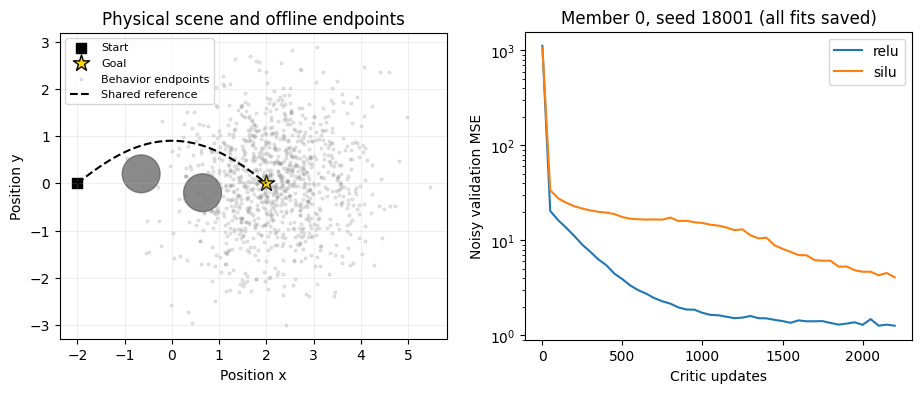

In [4]:
# Scene and ALL training endpoints for the first predefined seed; no cherry-picked paths.
def draw_scene(axis):
    for cx, cy, radius in CFG.obstacles:
        axis.add_patch(Circle((cx, cy), radius, color='.35', alpha=.7))
    axis.scatter(*CFG.start[:2], marker='s', c='black', s=60, label='Start')
    axis.scatter(*CFG.goal[:2], marker='*', c='gold', edgecolors='black', s=150, label='Goal')
    axis.set(xlabel='Position x', ylabel='Position y', aspect='equal')
    axis.grid(alpha=.2)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
draw_scene(axes[0])
points = DATA[SEEDS[0]]['x'].numpy()
axes[0].scatter(points[:, 0], points[:, 1], s=4, alpha=.18, c='gray', label='Behavior endpoints')
reference_curve = torch.stack([reference(t, CFG)[0] for t in np.linspace(0, CFG.horizon, 100)]).numpy()
axes[0].plot(reference_curve[:, 0], reference_curve[:, 1], 'k--', label='Shared reference')
axes[0].set(title='Physical scene and offline endpoints')
axes[0].legend(fontsize=8)
for activation in ('relu', 'silu'):
    rows = FITS[SEEDS[0], activation][0]['history']
    axes[1].plot([r['step'] for r in rows], [r['noisy_validation_mse'] for r in rows], label=activation)
axes[1].set(xlabel='Critic updates', ylabel='Noisy validation MSE', yscale='log',
            title='Member 0, seed 18001 (all fits saved)')
axes[1].legend()
savefig(fig, '01_scene_and_critic_training')

## 3. 原始 lean AM + Adam 的完整实现

Euler 离散：\(F=I+\Delta t A\)，\(\hat a_K=\nabla\hat g(X_K)\)。
对每条冻结轨迹，自后向前递推
\[
y_k=-S^\top\hat a_{k+1},\qquad
\hat a_k=F^\top\hat a_{k+1}+\Delta t\,\nabla\ell(X_k).
\]
然后最小化
\[
L_{\rm leanAM}(\theta)=
\frac{\Delta t}{2B}\sum_{i,k}\|u_\theta(X_k^i,t_k)-\operatorname{stopgrad}(y_k^i)\|^2 .
\]
注意监督使用 \(a_{k+1}\)，不是 \(a_k\)。rollout 与标签均 stop-gradient。
没有 \(D_xu_\theta\) 项，**所有对照都是 lean adjoint**。
对 scalar critic 的 autograd 取梯度，再平均五个 member 的终点梯度。
参数梯度 clip 到范数 5，交给默认 Adam（lr .002，betas .9/.999，eps 1e-8）。

这不是“对真实代价直接反向传播”，也不把 lean AM 的匹配梯度等同于 \(\nabla_\theta J\)。
框架背景：[Adjoint Matching §5.2](https://arxiv.org/html/2409.08861)。

In [5]:
def raw_gradient(critic, x):
    with torch.enable_grad():
        z = x.detach().requires_grad_(True)
        return torch.autograd.grad(critic(z).sum(), z)[0].detach()


def flat_grad(loss, actor, retain_graph=False):
    return torch.cat([g.flatten() for g in torch.autograd.grad(
        loss, actor.parameters(), retain_graph=retain_graph)])


def matching_gradients(actor, paths, terminals, cfg):
    """terminals shape [members, batch, state]; labels are fully detached."""
    batch, _, dim = paths.shape
    x = paths[:, :-1].detach().reshape(-1, dim).requires_grad_(False)
    t = (torch.arange(cfg.steps)*cfg.dt)[None, :, None].expand(batch, -1, -1)
    u = actor(x, t.reshape(-1, 1)).reshape(batch, cfg.steps, -1)
    _, f, sigma = matrices(cfg)
    running = running_cost_and_gradient(paths[:, :-1], cfg)[1]
    with torch.no_grad():
        a = terminals.clone()
        targets = []
        for k in range(cfg.steps-1, -1, -1):
            targets.append(-a @ sigma)
            a = a @ f + cfg.dt*running[:, k][None]
        targets = torch.stack(targets[::-1], 2)
    losses = .5*(u[None]-targets).square().sum(-1).sum(-1).mean(-1)*cfg.dt
    qs = torch.stack([flat_grad(loss, actor, retain_graph=i+1<len(losses))
                      for i, loss in enumerate(losses)])
    return qs.detach(), targets, losses.detach()


def proposal(actor, optimizer, paths, critics, cfg):
    terminals = torch.stack([raw_gradient(c, paths[:, -1]) for c in critics]).mean(0, keepdim=True)
    qs, _, losses = matching_gradients(actor, paths, terminals, cfg)
    mean = qs.mean(0)
    optimizer.zero_grad()
    offset = 0
    for p in actor.parameters():
        p.grad = mean[offset:offset+p.numel()].reshape_as(p).clone()
        offset += p.numel()
    torch.nn.utils.clip_grad_norm_(actor.parameters(), 5.)
    optimizer.step()
    return dict(loss=losses.mean().item(), matching_gradient_norm=mean.norm().item())


@contextmanager
def no_oracle_access():
    """Every actor update/guard runs with forbidden evaluator functions."""
    names = ('true_terminal_value', 'true_terminal_gradient', 'observed_terminal_cost')
    saved = {name: globals()[name] for name in names}
    def forbidden(*args, **kwargs):
        raise AssertionError('Actor training tried to access a true/observed terminal oracle')
    try:
        for name in names:
            globals()[name] = forbidden
        yield
    finally:
        globals().update(saved)

## 4. 改进候选：有限代价差的 nominal / minimax guard

AM 先做 20 次**完全不变的 Adam 提议**，从 \(\theta_0\) 到 \(\theta_1\)。
检查 \(\theta_\alpha=\theta_0+\alpha(\theta_1-\theta_0)\)，
\(\alpha\in\{0,.25,.5,1\}\)，每个候选使用同一组 320 条 Brownian 噪声。
对每个 scalar critic \(g_m\)，计算包括真实已知 running/energy 项的**模型**代价差
\(d_m(\alpha)=\hat J_m(\theta_\alpha)-\hat J_m(\theta_0)\)。

验证集 residual \(r_{im}=g_m(x_i)-y_i\)，\(C=N_{\rm val}^{-1}r^\top r\)，
\(\pi_m=1/5\)。不确定集合为
\[
\mathcal W=\{w\ge0:\mathbf1^\top w=1,\
D_{\rm KL}(w\|\pi)\le .3,\quad w^\top Cw\le1.1\,\pi^\top C\pi+10^{-10}\}.
\]
**同一 \(w\)** 对 incumbent/candidate、所有时刻和所有轨迹生效，避免对每个时刻
单独伪造终点代价。Robust guard 选
\[
\alpha^*=\arg\min_\alpha\max_{w\in\mathcal W} w^\top d(\alpha).
\]
Nominal guard 则将 \(w\) 固定为 \(\pi\)。\(\alpha=0\) 提供经验不增的后备选择。
这是对**有限候选集合/抽样模型代价**的检查，不是对真实 \(J\) 的保证。
SLSQP 的可行性及 incumbent 下界检查是必要检查，并非独立全局最优证书；
仓库历史审计的 6 个严格 support-certificate 警告仍然保留，不在本 notebook 抹去。

**预算**：guard 额外 50×4×320=64000 条模型轨迹；
AM 2x 用同样总数 128000 条轨迹全部做 AM 更新。
模型轨迹数相等，不意味着 wall-clock、网络反向或 critic 查询计算量相等。
参数被插值/拒绝时 **Adam moments 仍保留所有提议步的更新**；没有偷偷重置优化器。

SiLU 消融不使用 guard，只替换已拟合的终点 estimator，之后仍是相同 lean AM。

In [6]:
def vector(actor):
    return torch.nn.utils.parameters_to_vector(actor.parameters()).detach().clone()


@torch.no_grad()
def assign(actor, value):
    torch.nn.utils.vector_to_parameters(value.clone(), actor.parameters())


class Adversary:
    def __init__(self, value_gram, rho, slack=.1):
        self.m = len(value_gram)
        self.pi = np.ones(self.m)/self.m
        self.rho = rho
        self.value_gram = value_gram
        self.limit = float(self.pi @ value_gram @ self.pi)*(1+slack)+1e-10
        self.c = value_gram/max(self.limit, 1e-12)

    def kl(self, w):
        return float(np.sum(w*np.log(np.maximum(w, 1e-15)/self.pi)))

    def constraints(self):
        return [dict(type='eq', fun=lambda w: w.sum()-1, jac=lambda w: np.ones(self.m)),
                dict(type='ineq', fun=lambda w: self.rho-self.kl(w),
                     jac=lambda w: -(np.log(np.maximum(w, 1e-15)/self.pi)+1)),
                dict(type='ineq', fun=lambda w: 1-w@self.c@w, jac=lambda w: -2*self.c@w)]

    def violation(self, w):
        return max(abs(w.sum()-1), max(0., -float(w.min())),
                   max(0., self.kl(w)-self.rho), max(0., float(w@self.c@w)-1))


@torch.no_grad()
def validation_matrix(critics, data):
    errors = torch.stack([c(data['xvalid'])-data['yvalid'] for c in critics], 1).double().numpy()
    return errors.T @ errors / len(errors)


@torch.no_grad()
def model_costs(actor, cfg, critics, seed, n):
    paths, u = rollout(actor, cfg, n, rng(seed))
    known = .5*cfg.dt*u.square().sum((-1, -2))
    known += cfg.dt*running_cost_and_gradient(paths[:, :-1], cfg)[0].sum(-1)
    return torch.stack([known+c(paths[:, -1]) for c in critics], -1).double().numpy()


def worst_difference(member_difference, adversary):
    d = np.asarray(member_difference, dtype=np.float64)
    if adversary.rho == 0 or np.ptp(d) < 1e-12:
        return float(d @ adversary.pi), adversary.pi.copy(), 0.
    scale = max(float(np.ptp(d)), 1e-10)
    objective = (d-d.mean())/scale
    result = minimize(lambda w: -float(w @ objective), adversary.pi,
                      jac=lambda w: -objective, method='SLSQP',
                      bounds=[(1e-12, 1.)]*len(d), constraints=adversary.constraints(),
                      options=dict(ftol=1e-11, maxiter=300))
    if not result.success or adversary.violation(result.x) > 1e-7:
        raise RuntimeError(f'Value adversary failed: {result.message}')
    w = result.x
    assert w @ d >= adversary.pi @ d - 1e-8
    return float(w @ d), w, adversary.violation(w)


def guard(actor, before, proposed, cfg, critics, seed, options, adversary, robust):
    costs = []
    for alpha in options.alphas:
        assign(actor, before+alpha*(proposed-before))
        costs.append(model_costs(actor, cfg, critics, seed, options.guard_paths))
    differences = [np.mean(cost-costs[0], axis=0) for cost in costs]
    scores, weights, violations = [], [], []
    for delta in differences:
        if robust:
            score, w, violation = worst_difference(delta, adversary)
        else:
            score, w, violation = float(delta.mean()), adversary.pi.copy(), 0.
        scores.append(score)
        weights.append(w.tolist())
        violations.append(violation)
    selected = int(np.argmin(scores))
    assert scores[selected] <= 1e-9
    alpha = options.alphas[selected]
    assign(actor, before+alpha*(proposed-before))
    return dict(alpha=alpha, scores=scores, member_differences=[d.tolist() for d in differences],
                weights=weights, max_constraint_violation=max(violations),
                proposed_step_norm=float((proposed-before).norm()))


def audit_numerics():
    """Check equations, not efficacy; same tests run regardless of method ranking."""
    torch.manual_seed(8712)
    actor = Controller(CFG.actor_width)
    paths, _ = rollout(actor, CFG, 11, rng(734))
    z = paths[:, -1].detach().requires_grad_(True)
    automatic = torch.autograd.grad(true_terminal_value(z, CFG).sum(), z)[0]
    check('Analytic evaluation derivative agrees with autograd',
          torch.allclose(automatic, true_terminal_gradient(z.detach(), CFG), atol=2e-5, rtol=2e-5))
    clean = true_terminal_gradient(paths[:, -1], CFG)
    learned = torch.stack([raw_gradient(c, paths[:, -1]) for c in CRITICS[SEEDS[0], 'relu']]).mean(0)
    qs, targets, _ = matching_gradients(actor, paths, torch.stack([clean, learned]), CFG)
    _, f, sigma = matrices(CFG)
    error = learned-clean
    expected = []
    for k in range(CFG.steps-1, -1, -1):
        expected.append(-error @ sigma)
        error = error @ f
    propagated = torch.stack(expected[::-1], 1)
    check('Terminal error propagation matches lean target difference',
          torch.allclose(targets[1]-targets[0], propagated, atol=2e-5, rtol=2e-5))
    times = (torch.arange(CFG.steps)*CFG.dt)[None, :, None].expand(len(paths), -1, -1)
    prediction = actor(paths[:, :-1].reshape(-1, 4), times.reshape(-1, 1)).reshape(len(paths), CFG.steps, 2)
    projected = flat_grad(-(prediction*propagated).sum()/len(paths)*CFG.dt, actor)
    check('Target error projected through actor Jacobian equals parameter-gradient error',
          torch.allclose(qs[1]-qs[0], projected, atol=3e-5, rtol=3e-5))
    c = validation_matrix(CRITICS[SEEDS[0], 'relu'], DATA[SEEDS[0]])
    before = vector(actor)
    with no_oracle_access():
        proposal(actor, torch.optim.Adam(actor.parameters(), lr=OPT.lr),
                 paths, CRITICS[SEEDS[0], 'relu'], CFG)
        proposed = vector(actor)
        info = guard(actor, before, proposed, CFG, CRITICS[SEEDS[0], 'relu'], 89,
                     Options(guard_paths=16), Adversary(c, .3), True)
    check('Proposal and guard complete while all terminal oracles forbidden', True)
    check('Guard includes exact zero-difference incumbent', info['scores'][0] == 0.)
    difference = np.array([-.4, .2, .7, -.1, .3])
    value, w, _ = worst_difference(difference, Adversary(c, 0.))
    check('Zero uncertainty radius equals nominal guard', abs(value-difference.mean()) < 1e-10)
    torch.manual_seed(721)
    a = make_critic(CFG.critic_width, 'relu')
    torch.manual_seed(721)
    b = make_critic(CFG.critic_width, 'silu')
    check('Activation ablation preserves initial parameters exactly',
          all(torch.equal(x, y) for x, y in zip(a.parameters(), b.parameters())))
    display(pd.DataFrame(CHECKS))


audit_numerics()

,name,passed
0,Analytic evaluation derivative agrees with aut...,True
1,Terminal error propagation matches lean target...,True
2,Target error projected through actor Jacobian ...,True
3,Proposal and guard complete while all terminal...,True
4,Guard includes exact zero-difference incumbent,True
5,Zero uncertainty radius equals nominal guard,True
6,Activation ablation preserves initial paramete...,True


## 5. 训练、checkpoint 与不泄漏真值的边界

每个方法同 seed 的 actor 初始化相同，训练 RNG 从 seed+400000 开始。
guard 检查、周期评价、最终评价都使用与训练独立的随机数发生器。
AM 2x batch 更大，所以它的噪声序列分组不与 batch64 一一相同；不能谎称逐条轨迹一致。
其余方法在策略不同后轨迹状态也会不同，但输入随机数对齐。

保存 actor 与 Adam 在 0、500、1000 步的状态，并保存所有 guard 决策。
周期评价用 1024 条轨迹，仅记录；不 early stop，不挑最佳真实回报。
固定最终评价 4096 条轨迹，再以 80 个时间步 / 2048 条轨迹检查时间离散敏感性。
每次 actor 提议和 guard 调用都暂时禁止 `true_terminal_value/gradient`
及 `observed_terminal_cost`，若误用会直接报错，而不是只记录一个“零调用”的常量。

In [7]:
def train(seed, method, cfg, options):
    folder = OUT/f'seed_{seed}'/'actors'/method
    folder.mkdir(parents=True)
    critics = CRITICS[seed, 'silu' if method == 'silu' else 'relu']
    torch.manual_seed(seed+300000)
    actor = Controller(cfg.actor_width)
    optimizer = torch.optim.Adam(actor.parameters(), lr=options.lr)
    generator = rng(seed+400000)
    adversary = Adversary(validation_matrix(critics, DATA[seed]),
                          options.rho, options.validation_slack)
    batch = 2*options.batch if method == 'am_2x' else options.batch
    guarded = method.endswith('_guard')
    history, checks, checkpoints, blocks = [], [], {}, []
    started = time.monotonic()
    for step in range(options.updates+1):
        if step % options.eval_every == 0 or step == options.updates:
            history.append(dict(step=step, **evaluate(actor, cfg, seed+500000, n=1024)))
        if step in (0, options.updates//2, options.updates):
            snapshot = dict(step=step, actor=copy.deepcopy(actor.state_dict()),
                            optimizer=copy.deepcopy(optimizer.state_dict()))
            torch.save(snapshot, folder/f'checkpoint_{step}.pt')
            checkpoints[step] = snapshot
        if step == options.updates:
            break
        if guarded and step % options.block == 0:
            before = vector(actor)
        paths, _ = rollout(actor, cfg, batch, generator)
        with no_oracle_access():
            proposal(actor, optimizer, paths, critics, cfg)
            if guarded and (step+1) % options.block == 0:
                proposed = vector(actor)
                block = (step+1)//options.block
                info = guard(actor, before, proposed, cfg, critics,
                             seed+800000+block*10007, options, adversary, method == 'robust_guard')
                checks.append(dict(step=step+1, **info))
                blocks.append(dict(step=step+1, before=before, proposed=proposed, alpha=info['alpha']))
                # Adam moments intentionally retain every proposal update.
    final, arrays = evaluate(actor, cfg, seed+600000, n=options.final_paths, keep_paths=True)
    fine = evaluate(actor, cfg, seed+700000, n=2048, steps=2*cfg.steps)
    torch.save(actor.state_dict(), folder/'actor.pt')
    torch.save(blocks, folder/'blocks.pt')
    np.savez_compressed(folder/'evaluation.npz', **arrays)
    extra = options.updates//options.block*len(options.alphas)*options.guard_paths if guarded else 0
    result = dict(seed=seed, method=method, config=asdict(cfg), options=asdict(options),
                  final=final, fine_grid=fine, history=history, checks=checks,
                  seconds=time.monotonic()-started,
                  actor_training_rollouts=options.updates*batch, extra_model_rollouts=extra,
                  total_training_model_rollouts=options.updates*batch+extra,
                  extra_critic_value_queries=extra*len(critics),
                  true_terminal_access_during_actor_updates='forbidden at runtime',
                  additional_real_terminal_queries=0, adjoint='lean', optimizer='Adam',
                  optimizer_state_policy='All proposal moments retained; interpolate parameters only.')
    (folder/'result.json').write_text(json.dumps(result, indent=2))
    print(f'{seed} {method}: J={final["cost"]:.6f}, success={final["success"]:.3f}, '
          f'{result["seconds"]:.1f}s', flush=True)
    return result, actor, checkpoints


RESULTS, ACTORS, CHECKPOINTS = {}, {}, {}
for seed in SEEDS:
    for method in METHODS:
        RESULTS[seed, method], ACTORS[seed, method], CHECKPOINTS[seed, method] = train(seed, method, CFG, OPT)

18001 am_adam: J=19.475227, success=0.812, 5.8s


18001 am_2x: J=19.166279, success=0.853, 7.9s


18001 nominal_guard: J=19.570673, success=0.806, 7.4s


18001 robust_guard: J=19.751617, success=0.805, 7.6s


18001 silu: J=19.801819, success=0.776, 6.1s


...

18003 am_adam: J=19.842176, success=0.818, 5.8s


18003 am_2x: J=19.304691, success=0.858, 8.0s


18003 nominal_guard: J=19.862387, success=0.776, 7.5s


18003 robust_guard: J=19.862083, success=0.789, 7.5s


18003 silu: J=20.369545, success=0.691, 5.9s


## 6. 测评：逐 seed、配对差、预算与细网格

代价越低越好。对每个 seed 计算相对于同 seed 原始 AM 的百分比降低，
再报告三 seed 的均值；同时报告“均值代价之比”的百分比，避免统计口径混用。
95% t 区间针对三个训练 seeds 的**配对代价差均值**，不是 4096 条轨迹当独立训练样本。
n=3 很小，且这些是此前开发中已使用的 seeds；区间只描述结果，不构成独立确认。
即便一个候选在某个 seed 胜出，也不能写成“已证明优于 AM”。

下面的三个面板参照“学习曲线—轨迹—汇总”的展示形式，但数值全部由上面真实训练产生。
不使用任意归一化到 0–100 的分数，不挑最好 seed。轨迹显示第一个预定 seed，
全部方法使用同一批噪声；均值路线本身不能代替碰撞率。

,seed,method,cost,cost_mc_se,energy,running,terminal,success,collision,distance,speed,fine_cost,training_rollouts,guard_rollouts,total_rollouts,extra_value_queries
0,18001,am_adam,19.475227,0.090356,2.716499,2.987583,13.771145,0.812500,0.001221,0.196676,0.317642,19.049042,64000,0,64000,0
1,18001,am_2x,19.166279,0.084949,2.781101,3.159797,13.225380,0.853027,0.003662,0.204525,0.286809,19.439640,128000,0,128000,0
2,18001,nominal_guard,19.570673,0.090464,2.605422,2.972243,13.993008,0.805664,0.001465,0.202776,0.320029,19.764622,64000,64000,128000,320000
3,18001,robust_guard,19.751617,0.091127,2.573888,3.041118,14.136611,0.805420,0.002686,0.208695,0.319350,19.912380,64000,64000,128000,320000
4,18001,silu,19.801819,0.094536,1.933441,3.142386,14.725992,0.775879,0.003174,0.236278,0.309313,19.867037,64000,0,64000,0
5,18002,am_adam,19.085798,0.083802,2.530154,2.586263,13.969381,0.823975,0.001709,0.217889,0.303595,19.160536,64000,0,64000,0
6,18002,am_2x,19.770586,0.084630,2.841195,3.043827,13.885564,0.825439,0.001709,0.228523,0.285597,20.787495,128000,0,128000,0
7,18002,nominal_guard,19.404249,0.089272,2.389829,3.055341,13.959077,0.815186,0.003174,0.208053,0.313920,19.772945,64000,64000,128000,320000
8,18002,robust_guard,19.312782,0.088914,2.393947,2.875280,14.043556,0.806152,0.001953,0.207101,0.318240,19.499458,64000,64000,128000,320000
9,18002,silu,20.355074,0.094078,1.726539,2.404671,16.223866,0.689209,0.000732,0.268516,0.332283,20.135363,64000,0,64000,0


,method,mean_cost,seed_cost_sd,success,collision,mean_paired_reduction_pct,reduction_of_mean_cost_pct,wins,paired_cost_delta,delta_CI95_low,delta_CI95_high,fine_mean_cost
0,am_adam,19.467734,0.378245,0.818115,0.001628,0.000000,0.000000,0,0.000000,0.000000,0.000000,19.544518
1,am_2x,19.413852,0.316597,0.845459,0.003906,0.235741,0.276776,2,-0.053882,-1.668155,1.560391,19.923893
2,nominal_guard,19.612436,0.231907,0.798910,0.002035,-0.753488,-0.743293,0,0.144702,-0.240592,0.529996,19.860149
3,robust_guard,19.642161,0.290549,0.800212,0.002197,-0.902932,-0.895980,0,0.174427,-0.163613,0.512467,19.918139
4,silu,20.175479,0.323680,0.718750,0.001709,-3.661714,-3.635478,0,0.707745,-0.525762,1.941252,19.930091


,training_rollouts,guard_rollouts,total_rollouts,extra_value_queries
method,,,,
am_adam,64000,0,64000,0
am_2x,128000,0,128000,0
nominal_guard,64000,64000,128000,320000
robust_guard,64000,64000,128000,320000
silu,64000,0,64000,0


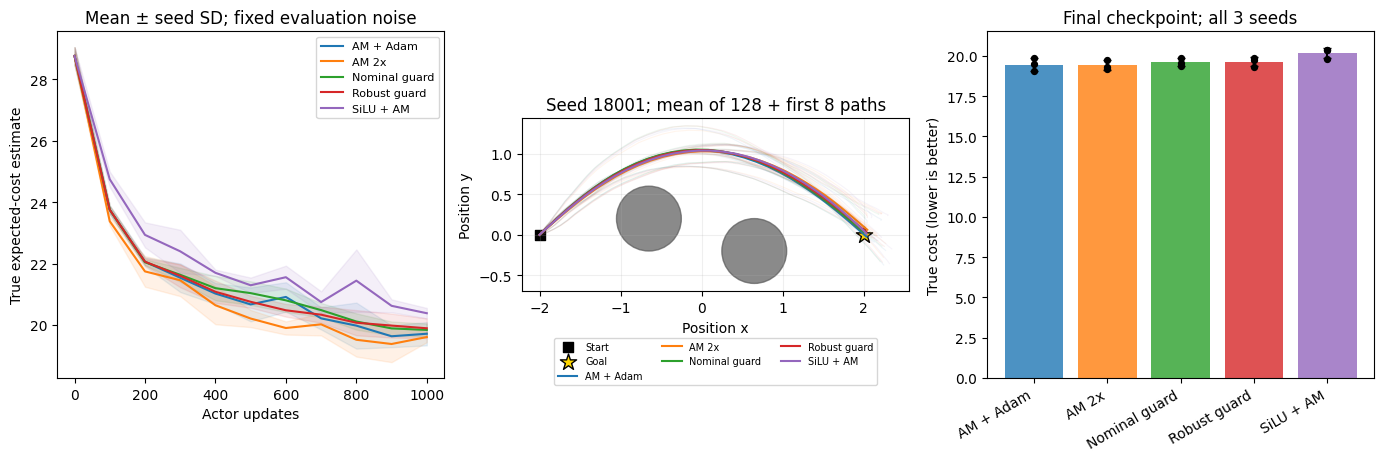

In [8]:
FINAL = pd.DataFrame([dict(seed=s, method=m, **r['final'],
                           fine_cost=r['fine_grid']['cost'],
                           training_rollouts=r['actor_training_rollouts'],
                           guard_rollouts=r['extra_model_rollouts'],
                           total_rollouts=r['total_training_model_rollouts'],
                           extra_value_queries=r['extra_critic_value_queries'])
                      for (s, m), r in RESULTS.items()])
BASELINE = FINAL[FINAL.method == 'am_adam'].set_index('seed')
AGG_ROWS = []
for method in METHODS:
    rows = FINAL[FINAL.method == method].set_index('seed').loc[list(SEEDS)]
    delta = (rows.cost-BASELINE.loc[list(SEEDS)].cost).to_numpy()
    paired_pct = (-100*delta/BASELINE.loc[list(SEEDS)].cost.to_numpy())
    ci = student_t.ppf(.975, len(SEEDS)-1)*delta.std(ddof=1)/math.sqrt(len(SEEDS))
    AGG_ROWS.append(dict(method=method, mean_cost=rows.cost.mean(), seed_cost_sd=rows.cost.std(ddof=1),
                         success=rows.success.mean(), collision=rows.collision.mean(),
                         mean_paired_reduction_pct=paired_pct.mean(),
                         reduction_of_mean_cost_pct=100*(1-rows.cost.mean()/BASELINE.cost.mean()),
                         wins=int((delta < 0).sum()), paired_cost_delta=delta.mean(),
                         delta_CI95_low=delta.mean()-ci, delta_CI95_high=delta.mean()+ci,
                         fine_mean_cost=rows.fine_cost.mean()))
AGG = pd.DataFrame(AGG_ROWS)
display(FINAL)
display(AGG)
display(FINAL.groupby('method', sort=False)[['training_rollouts', 'guard_rollouts',
                                             'total_rollouts', 'extra_value_queries']].first())
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
colors = dict(zip(METHODS, plt.get_cmap('tab10').colors[:len(METHODS)]))
for method in METHODS:
    histories = [RESULTS[s, method]['history'] for s in SEEDS]
    x = [p['step'] for p in histories[0]]
    y = np.array([[p['cost'] for p in history] for history in histories])
    axes[0].plot(x, y.mean(0), label=LABELS[method], color=colors[method])
    axes[0].fill_between(x, y.mean(0)-y.std(0, ddof=1), y.mean(0)+y.std(0, ddof=1),
                         alpha=.10, color=colors[method])
axes[0].set(xlabel='Actor updates', ylabel='True expected-cost estimate',
            title='Mean ± seed SD; fixed evaluation noise')
axes[0].legend(fontsize=8)
draw_scene(axes[1])
for method in METHODS:
    paths, _ = rollout(ACTORS[SEEDS[0], method], CFG, 128, rng(810001))
    positions = paths[:, :, :2].numpy()
    for path in positions[:8]:  # First 8, never selected by success or reward.
        axes[1].plot(path[:, 0], path[:, 1], alpha=.07, color=colors[method], lw=.8)
    mean = positions.mean(0)
    axes[1].plot(mean[:, 0], mean[:, 1], label=LABELS[method], color=colors[method])
axes[1].set(title='Seed 18001; mean of 128 + first 8 paths')
axes[1].legend(fontsize=7, loc='upper center', bbox_to_anchor=(.5, -.24), ncol=3)
axes[2].bar(range(len(METHODS)), AGG.mean_cost, yerr=AGG.seed_cost_sd,
            color=[colors[m] for m in METHODS], alpha=.8, capsize=3)
for i, method in enumerate(METHODS):
    values = FINAL[FINAL.method == method].cost
    axes[2].scatter([i]*len(values), values, color='black', s=18, zorder=4)
axes[2].set_xticks(range(len(METHODS)), [LABELS[m] for m in METHODS], rotation=30, ha='right')
axes[2].set(ylabel='True cost (lower is better)', title='Final checkpoint; all 3 seeds')
savefig(fig, '02_training_trajectories_final_cost')

## 7. 回到 motivation：终点误差 → 中间标签 → actor 参数梯度

**训练完成后**，只在原始 AM 的固定末次 checkpoint 上采样共同的 1024 条路径。
对这批完全相同的路径，分别代入 learned / oracle 终点梯度：
\[
\delta y_k=-S^\top(F^\top)^{K-1-k}e_K,\qquad
\delta q=-\frac{\Delta t}{B}\sum_{i,k}
(D_\theta u(X_k^i,t_k))^\top \delta y_k^i .
\]
（代码按行向量存储，所以矩阵乘法方向转置。）
报告 value RMSE、gradient RMSE、相对误差、不同中间时刻的监督误差、
参数梯度误差及 learned/oracle 匹配梯度余弦。
这里的“oracle 匹配梯度”仍不是完整的真实成本梯度。

这些是共同轨迹上的标签替换诊断，**不是**重新训练一个 oracle actor，也不自动证明性能损失
全由梯度误差导致。严格隔离与因果干预的可解析证据见第一份 notebook。
ensemble 方差本身也不等于准确度：共同偏差可能让所有 member 一致地出错。

,seed,value_RMSE,relative_value_RMSE,gradient_RMSE,relative_gradient_RMSE,integrated_target_error,matching_gradient_error,relative_matching_gradient_error,matching_gradient_cosine,ensemble_gradient_variance
0,18001,2.776717,0.190964,10.466306,0.303275,12.033607,9.450395,0.358948,0.983647,52.306507
1,18002,4.954638,0.330271,15.762242,0.441478,26.051764,19.097673,0.474013,0.960919,42.370232
2,18003,2.527085,0.169964,11.375975,0.315641,14.137300,20.762686,0.476189,0.967652,53.009605


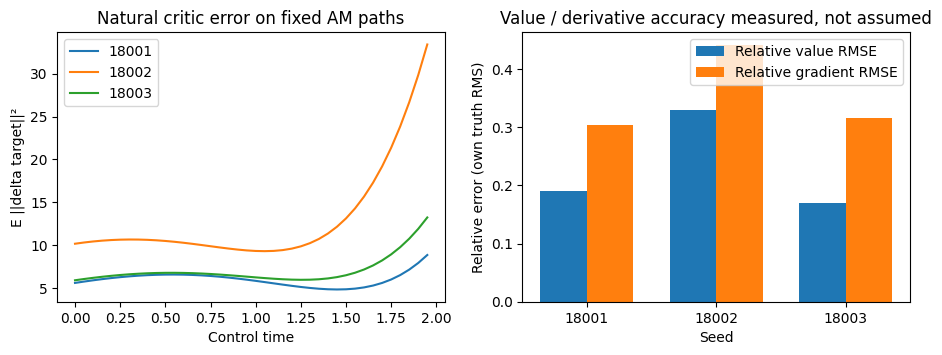

In [9]:
DIAGNOSTICS, TIME_ERRORS = [], []
for seed in SEEDS:
    actor = ACTORS[seed, 'am_adam']
    paths, _ = rollout(actor, CFG, 1024, rng(seed+910000))
    critics = CRITICS[seed, 'relu']
    endpoint = paths[:, -1]
    with torch.no_grad():
        values = torch.stack([c(endpoint) for c in critics]).mean(0)
        truth = true_terminal_value(endpoint, CFG)
    member_z = torch.stack([raw_gradient(c, endpoint) for c in critics])
    estimated_z = member_z.mean(0)
    true_z = true_terminal_gradient(endpoint, CFG)
    qs, targets, _ = matching_gradients(actor, paths, torch.stack([true_z, estimated_z]), CFG)
    time_error = (targets[1]-targets[0]).square().sum(-1).mean(0).numpy()
    value_rmse = (values-truth).square().mean().sqrt().item()
    gradient_rmse = (estimated_z-true_z).square().sum(-1).mean().sqrt().item()
    DIAGNOSTICS.append(dict(
        seed=seed, value_RMSE=value_rmse,
        relative_value_RMSE=value_rmse/truth.square().mean().sqrt().item(),
        gradient_RMSE=gradient_rmse,
        relative_gradient_RMSE=gradient_rmse/true_z.square().sum(-1).mean().sqrt().item(),
        integrated_target_error=CFG.dt*time_error.sum().item(),
        matching_gradient_error=(qs[1]-qs[0]).norm().item(),
        relative_matching_gradient_error=((qs[1]-qs[0]).norm()/qs[0].norm().clamp_min(1e-12)).item(),
        matching_gradient_cosine=torch.nn.functional.cosine_similarity(qs[0], qs[1], dim=0).item(),
        ensemble_gradient_variance=(member_z-estimated_z).square().sum(-1).mean().item()))
    TIME_ERRORS.append(time_error)
DIAG = pd.DataFrame(DIAGNOSTICS)
display(DIAG)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for seed, values in zip(SEEDS, TIME_ERRORS):
    axes[0].plot(np.arange(CFG.steps)*CFG.dt, values, label=str(seed))
axes[0].set(xlabel='Control time', ylabel='E ||delta target||²',
            title='Natural critic error on fixed AM paths')
axes[0].legend()
locations = np.arange(len(SEEDS))
axes[1].bar(locations-.18, DIAG.relative_value_RMSE, width=.36, label='Relative value RMSE')
axes[1].bar(locations+.18, DIAG.relative_gradient_RMSE, width=.36, label='Relative gradient RMSE')
axes[1].set_xticks(locations, SEEDS)
axes[1].set(xlabel='Seed', ylabel='Relative error (own truth RMS)',
            title='Value / derivative accuracy measured, not assumed')
axes[1].legend()
savefig(fig, '03_natural_gradient_propagation')

## 8. 保存实际结果与结论边界

本实验只能评价已实现的候选。失败结果照常保留：
“动机在解析例子中成立”与“某个算法成功解决问题”是两个不同命题。
不用换场景、挑 seed 或省略预算对照来把负结果变成超越 AM 的证据。
下面的胜负表来自当前运行，不从历史文字复制。

In [10]:
for method in METHODS[1:]:
    row = AGG[AGG.method == method].iloc[0]
    direction = '降低' if row.mean_paired_reduction_pct > 0 else '增加'
    display(Markdown(
        f'- **{LABELS[method]}**：相对于同 seed AM，平均真实代价{direction} '
        f'**{abs(row.mean_paired_reduction_pct):.3f}%**，**{row.wins}/3** seeds 胜出；'
        f'固定末次平均代价 **{row.mean_cost:.6f}**。'))
display(Markdown(
    f'**自然误差诊断**：同一批末次 AM 路径上的相对 value RMSE 为 '
    f'**{100*DIAG.relative_value_RMSE.min():.1f}%–{100*DIAG.relative_value_RMSE.max():.1f}%**，'
    f'相对 gradient RMSE 为 **{100*DIAG.relative_gradient_RMSE.min():.1f}%–'
    f'{100*DIAG.relative_gradient_RMSE.max():.1f}%**；learned/oracle 匹配梯度余弦为 '
    f'**{DIAG.matching_gradient_cosine.min():.3f}–{DIAG.matching_gradient_cosine.max():.3f}**。'
    '这里确实测到了标签及参数梯度变化，但不能把 17%–33% 的值误差说成“值已经非常准确”，'
    '也不能把较大的误差范数直接说成更新方向已经失效。自然任务中的完整因果性能归因仍未建立。'))
display(Markdown(
    '**解读**：这次只是复现既有开发协议，并未增加独立确认 seeds。'
    '即使某个平均值更好，也不能把三个已使用 seeds 的结果写成普遍优越性。'
    '本 notebook 没有推出新的最优控制方程；其价值是把实现、预算、标签传播和负结果公开到可逐行检查。'))
guard_checks = [c for (s, m), r in RESULTS.items() for c in r['checks']]
check('All selected empirical model scores nonpositive',
      all(min(c['scores']) <= 1e-9 for c in guard_checks))
check('All support optimizations satisfy tested feasibility tolerance',
      all(c['max_constraint_violation'] <= 1e-7 for c in guard_checks))
check('All 15 fixed-seed training runs retained', len(RESULTS) == len(SEEDS)*len(METHODS))
check('All frozen protocol fields unchanged',
      hashlib.sha256(json.dumps(PROTOCOL, sort_keys=True).encode()).hexdigest() == PROTOCOL_SHA)
summary = dict(protocol=PROTOCOL, protocol_sha256=PROTOCOL_SHA, versions=VERSIONS,
               final=FINAL.to_dict(orient='records'), aggregate=AGG.to_dict(orient='records'),
               diagnostics=DIAGNOSTICS, assertions=CHECKS,
               trained_critics=30, trained_actors=len(RESULTS),
               historical_support_certificate_warnings=6,
               solver_claim='Feasibility/incumbent checks only; not an independent support certificate',
               execution_seconds=time.monotonic()-START)
(OUT/'summary.json').write_text(json.dumps(summary, indent=2, allow_nan=False))
np.savez_compressed(OUT/'time_resolved_target_error.npz', seeds=SEEDS, values=np.stack(TIME_ERRORS))
display(pd.DataFrame(CHECKS))
print(f'Finished {len(RESULTS)} actor runs and 30 critic fits; {time.monotonic()-START:.1f}s.')
print('Outputs:', Path('runs')/OUT.name)

- **AM 2x**：相对于同 seed AM，平均真实代价降低 **0.236%**，**2/3** seeds 胜出；固定末次平均代价 **19.413852**。

- **Nominal guard**：相对于同 seed AM，平均真实代价增加 **0.753%**，**0/3** seeds 胜出；固定末次平均代价 **19.612436**。

- **Robust guard**：相对于同 seed AM，平均真实代价增加 **0.903%**，**0/3** seeds 胜出；固定末次平均代价 **19.642161**。

- **SiLU + AM**：相对于同 seed AM，平均真实代价增加 **3.662%**，**0/3** seeds 胜出；固定末次平均代价 **20.175479**。

**自然误差诊断**：同一批末次 AM 路径上的相对 value RMSE 为 **17.0%–33.0%**，相对 gradient RMSE 为 **30.3%–44.1%**；learned/oracle 匹配梯度余弦为 **0.961–0.984**。这里确实测到了标签及参数梯度变化，但不能把 17%–33% 的值误差说成“值已经非常准确”，也不能把较大的误差范数直接说成更新方向已经失效。自然任务中的完整因果性能归因仍未建立。

**解读**：这次只是复现既有开发协议，并未增加独立确认 seeds。即使某个平均值更好，也不能把三个已使用 seeds 的结果写成普遍优越性。本 notebook 没有推出新的最优控制方程；其价值是把实现、预算、标签传播和负结果公开到可逐行检查。

,name,passed
0,Analytic evaluation derivative agrees with aut...,True
1,Terminal error propagation matches lean target...,True
2,Target error projected through actor Jacobian ...,True
3,Proposal and guard complete while all terminal...,True
4,Guard includes exact zero-difference incumbent,True
5,Zero uncertainty radius equals nominal guard,True
6,Activation ablation preserves initial paramete...,True
7,All selected empirical model scores nonpositive,True
8,All support optimizations satisfy tested feasi...,True
9,All 15 fixed-seed training runs retained,True


Finished 15 actor runs and 30 critic fits; 120.3s.
Outputs: runs/02-navigation-2fw58vgu
